# Fine-tuning con LoRA: Qwen3-4B Variante: QLoRA: cuantizacion 4-bit NF4 + LoRA r=8 sobre q/k/v_proj

Este notebook realiza el fine-tuning del modelo **Qwen3-4B** mediante **LoRA** (Low-Rank Adaptation) para la tarea de clasificacion ideologica de noticias espanolas en tres clases:
**IZQUIERDA**, **CENTRO** y **DERECHA**.

## 1. Montar Google Drive


In [69]:
from google.colab import drive
import os

drive.mount('/content/drive')

assert os.path.exists('/content/drive/MyDrive'), (
    'Drive no montado correctamente. Vuelve a ejecutar esta celda.'
)
print('Drive montado correctamente')
print('Contenido de MyDrive/TFM (si existe):')
tfm_path = '/content/drive/MyDrive/TFM'
if os.path.exists(tfm_path):
    for item in sorted(os.listdir(tfm_path)):
        print(f'  {item}')
else:
    print('  La carpeta TFM no existe todavia en Drive. Se creara al guardar.')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Drive montado correctamente
Contenido de MyDrive/TFM (si existe):
  qwen3_4b_lora
  qwen3_4b_lora_mlp16
  qwen3_4b_lora_r8_qkv
  qwen3_4b_lora_regularized
  qwen3_4b_qlora
  splits


## 2. Instalación de dependencias e Imports

Todas las dependencias y todos los imports de Python se recogen en las celdas de esta sección.

In [70]:
# Verificar GPU antes de instalar
!nvidia-smi

!pip install -q --upgrade transformers>=4.51.0 peft>=0.14.0 \
             bitsandbytes accelerate datasets sentencepiece trl
!pip install -q lime
!pip install -q --upgrade torchao

Fri May 15 13:32:43 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA RTX PRO 6000 Blac...    Off |   00000000:05:00.0 Off |                    0 |
| N/A   39C    P0             91W /  600W |   11787MiB /  97887MiB |      0%      Default |
|                                         |                        |             Disabled |
+-----------------------------------------+-----

## 3. Imports y configuración global

Todos los imports de Python están en la celda siguiente.

In [72]:
import warnings
warnings.filterwarnings('ignore')

from pathlib import Path
from sklearn.metrics import (
    accuracy_score, f1_score,
    precision_recall_fscore_support,
    cohen_kappa_score, confusion_matrix,
)
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    TrainingArguments,
    Trainer,
    DataCollatorWithPadding,
    BitsAndBytesConfig,
)
from peft import LoraConfig, get_peft_model, TaskType, prepare_model_for_kbit_training
from datasets import Dataset

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd


import shap
import numpy as np
import torch
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import pandas as pd


import pandas as pd
import matplotlib.pyplot as plt
from scipy.special import log_softmax

from lime.lime_text import LimeTextExplainer
from IPython.display import display, HTML
import transformers
print(f'transformers version: {transformers.__version__}')

In [73]:
# Semilla global para reproducibilidad (permite comparar notebooks)
SEED = 42
import random, numpy as np, torch
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# Codificacion de etiquetas
LABEL2ID = {'IZQUIERDA': 0, 'CENTRO': 1, 'DERECHA': 2}
ID2LABEL = {v: k for k, v in LABEL2ID.items()}
CLASES   = ['IZQUIERDA', 'CENTRO', 'DERECHA']

MODEL_NAME = 'Qwen/Qwen3-4B'
OUTPUT_DIR = '/content/drive/MyDrive/TFM/qwen3_4b_qlora'

# Copiar datos de Drive a disco local para mayor velocidad
import shutil, os
os.makedirs('/content/splits', exist_ok=True)
shutil.copy('/content/drive/MyDrive/TFM/splits/df_train.parquet', '/content/splits/df_train.parquet')
shutil.copy('/content/drive/MyDrive/TFM/splits/df_val.parquet',   '/content/splits/df_val.parquet')
SPLITS_DIR = '/content/splits/'

# Crear carpeta de output si no existe
Path(OUTPUT_DIR).mkdir(parents=True, exist_ok=True)

# Verificar GPU
print(f'GPU disponible : {torch.cuda.is_available()}')
if torch.cuda.is_available():
    print(f'GPU            : {torch.cuda.get_device_name(0)}')
    print(f'VRAM total     : {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB')
print(f'SPLITS_DIR     : {SPLITS_DIR}')
print(f'OUTPUT_DIR     : {OUTPUT_DIR}')


GPU disponible : True
GPU            : NVIDIA RTX PRO 6000 Blackwell Server Edition
VRAM total     : 102.0 GB
SPLITS_DIR     : /content/splits/
OUTPUT_DIR     : /content/drive/MyDrive/TFM/qwen3_4b_qlora


## 4. Cargar datos de entrenamiento y validacion

Cargamos df_train y df_val desde Drive. La columna `texto` contiene el articulo
completo (titular + abstract + noticia) construido en el notebook de preprocesado.
La columna `final_label` contiene la etiqueta ideologica del ground truth.

df_test NO se carga aqui. Se reserva para la comparativa final de la Seccion 6, ya que si se usara aqui para ajustar hiperparametros dejaria de ser una medida honesta del modelo.

In [74]:
df_train = pd.read_parquet(SPLITS_DIR + 'df_train.parquet')
df_val   = pd.read_parquet(SPLITS_DIR + 'df_val.parquet')

# Verificar columnas
print('Columnas df_train:', df_train.columns.tolist())
assert 'texto' in df_train.columns, 'Columna texto no encontrada en df_train'
assert 'final_label' in df_train.columns, 'Columna final_label no encontrada en df_train'

print(f'\nTrain : {len(df_train):,} articulos')
print(f'Val   : {len(df_val):,} articulos')
print(f'\nDistribucion train:')
print(df_train['final_label'].value_counts().to_string())
print(f'\nDistribucion val:')
print(df_val['final_label'].value_counts().to_string())
print(f'\nLongitud media texto train : {df_train["texto"].str.len().mean():.0f} caracteres')
print(f'Longitud maxima texto train: {df_train["texto"].str.len().max():,} caracteres')


Columnas df_train: ['id', 'texto', 'medio', 'final_label', 'accion']

Train : 1,902 articulos
Val   : 238 articulos

Distribucion train:
final_label
CENTRO       766
IZQUIERDA    672
DERECHA      464

Distribucion val:
final_label
CENTRO       96
IZQUIERDA    84
DERECHA      58

Longitud media texto train : 4521 caracteres
Longitud maxima texto train: 32,165 caracteres


## 5. Cargar el modelo

Se usa AutoModelForSequenceClassification en lugar del modelo generativo porque:
- Añade una cabeza de clasificacion lineal sobre el transformer
- Es mas eficiente para clasificacion que generar texto token a token
- Permite obtener probabilidades directamente via softmax sobre los logits

In [75]:
print('Configurando cuantizacion 4-bit NF4...')
bnb_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type='nf4',
    bnb_4bit_compute_dtype=torch.bfloat16,
    bnb_4bit_use_double_quant=True,   # double quantization -> ahorro extra VRAM
)

print('Cargando tokenizer...')
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME, trust_remote_code=True)
if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token
print(f'Vocabulario: {tokenizer.vocab_size:,} tokens')

print('\nCargando modelo en 4-bit (1-2 min)...')
model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=3,
    id2label=ID2LABEL,
    label2id=LABEL2ID,
    quantization_config=bnb_config,
    device_map='auto',
    trust_remote_code=True,
)
model.config.pad_token_id = tokenizer.pad_token_id

# Prepara el modelo para entrenamiento en k-bit (importante para QLoRA)
model = prepare_model_for_kbit_training(model)

vram_used = torch.cuda.memory_allocated() / 1e9
print(f'Modelo cargado (4-bit) VRAM usada: {vram_used:.1f} GB')


Configurando cuantizacion 4-bit NF4...
Cargando tokenizer...
Vocabulario: 151,643 tokens

Cargando modelo en 4-bit (1-2 min)...


Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

[transformers] Qwen3ForSequenceClassification LOAD REPORT from: Qwen/Qwen3-4B
Key          | Status  | 
-------------+---------+-
score.weight | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Modelo cargado (4-bit) VRAM usada: 7.0 GB


## 6. Configurar QLoRA

**Variante: QLoRA QKV r8**

Se aplica cuantización 4-bit NF4 al modelo base y adaptadores LoRA sobre Q, K y V con rango r=8.

Parámetros clave de QLoRA:
- **Cuantización NF4 (4-bit)**: el modelo base se carga en 4-bit en lugar de bfloat16. Esto reduce el consumo de VRAM de ~8 GB a ~2.2 GB para Qwen3-4B, permitiendo ejecutar el fine-tuning en una GPU T4 de Colab con 15 GB.
- `r=8`, `lora_alpha=16`: mismo rango que las variantes LoRA estándar para comparar el efecto de la cuantización de forma aislada.
- `lora_dropout=0.1`: regularización estándar.
- `target_modules=['q_proj', 'k_proj', 'v_proj']`: mismas capas que QKV r8.

Con esta configuración se entrenan 3,988,992 parámetros (0.0991 % del total), idéntico a QKV r8. La diferencia es que los pesos del modelo base están cuantizados y el optimizador trabaja con los adaptadores en precisión completa (bfloat16) sobre los pesos congelados en NF4.

In [77]:
# QLoRA — r=8 sobre q/k/v, post cuantizacion 4-bit
lora_config = LoraConfig(
    task_type=TaskType.SEQ_CLS,
    r=8,
    lora_alpha=16,
    lora_dropout=0.1,
    target_modules=['q_proj', 'k_proj', 'v_proj'],
    bias='none',
)

model = get_peft_model(model, lora_config)
model.print_trainable_parameters()


trainable params: 3,988,992 || all params: 4,026,464,768 || trainable%: 0.0991


### Parámetros entrenables

Con r=8 sobre q_proj, k_proj y v_proj se entrenan **3,988,992 parámetros** (0.0991 % del total de Qwen3-4B), idéntico a LoRA QKV r8. La diferencia es el modelo base: en QLoRA está cuantizado en 4-bit NF4, reduciendo el consumo de VRAM de ~8 GB a ~2.2 GB.

Los adaptadores LoRA se entrenan en precisión completa (bfloat16) sobre el modelo base congelado y cuantizado. Esto permite el fine-tuning de un modelo de 4B parámetros en hardware con VRAM limitada (GPU T4 de 15 GB) a costa de introducir ruido de cuantización en las activaciones del modelo base.

## 7. Tokenizar los datasets

Convertimos los DataFrames de pandas a formato HuggingFace Dataset.

El tokenizer convierte el texto en secuencias de token IDs que el modelo entiende.
Se aplica truncado a max_length=1024 tokens cuando el articulo es mas largo.
No se trunca el texto manualmente antes: se pasa el campo texto completo
y el tokenizer decide el corte.

Con una longitud media de ~ 4,455 caracteres (~1,100 tokens), max_length=1024 cubre aproximadamente el 70 por ciento de los articulos completos.
La informacion ideologica relevante se concentra en el titular y los primeros parrafos, por lo que el truncado no supone una perdida significativa de senal.

padding=False en el tokenizer y DataCollatorWithPadding en el Trainer hacen padding
dinamico por batch: cada batch se padea solo hasta el ejemplo mas largo de ese batch,
no hasta max_length. Esto ahorra VRAM y acelera el entrenamiento.


In [78]:
MAX_LENGTH = 1024

def tokenize(batch):
    return tokenizer(
        batch['texto'],
        truncation=True,
        max_length=MAX_LENGTH,
        padding=False,
    )

def make_dataset(df):
    ds = Dataset.from_dict({
        'texto': df['texto'].tolist(),
        'label': df['final_label'].map(LABEL2ID).tolist(),
    })
    return ds.map(tokenize, batched=True, remove_columns=['texto'])

print('Tokenizando datasets...')
ds_train = make_dataset(df_train)
ds_val   = make_dataset(df_val)

print(f'Train: {len(ds_train):,} ejemplos')
print(f'Val  : {len(ds_val):,} ejemplos')
print(f'Columnas: {ds_train.column_names}')


Tokenizando datasets...


Map:   0%|          | 0/1902 [00:00<?, ? examples/s]

Map:   0%|          | 0/238 [00:00<?, ? examples/s]

Train: 1,902 ejemplos
Val  : 238 ejemplos
Columnas: ['label', 'input_ids', 'attention_mask']


## 8. Funcion de metricas

Las metricas que se calculan al final de cada epoca sobre el conjunto de validacion.

La metrica principal es F1-macro porque:
- Trata las tres clases (IZQUIERDA, CENTRO, DERECHA) por igual
- No se ve distorsionada por el desbalanceo de clases (CENTRO=40%, DERECHA=24%)
- Es el estandar en papers de clasificacion ideologica y de texto en general

El checkpoint que se guarda como mejor es el que maximiza F1-macro en validacion,no el del ultimo epoch.


In [79]:
def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=-1)

    acc      = accuracy_score(labels, preds)
    f1_macro = f1_score(labels, preds, average='macro',    labels=[0,1,2], zero_division=0)
    f1_w     = f1_score(labels, preds, average='weighted', labels=[0,1,2], zero_division=0)
    kappa    = cohen_kappa_score(labels, preds)

    probs     = torch.softmax(torch.tensor(logits, dtype=torch.float32), dim=-1).numpy()
    confianza = probs.max(axis=1).mean()

    prec, rec, f1_per, _ = precision_recall_fscore_support(
        labels, preds, labels=[0,1,2], zero_division=0
    )

    return {
        'accuracy':    round(acc, 4),
        'f1_macro':    round(f1_macro, 4),
        'f1_weighted': round(f1_w, 4),
        'kappa':       round(kappa, 4),
        'confianza':   round(float(confianza), 4),
        'f1_izq':      round(f1_per[0], 4),
        'f1_cen':      round(f1_per[1], 4),
        'f1_der':      round(f1_per[2], 4),
        'prec_izq':    round(prec[0], 4),
        'prec_cen':    round(prec[1], 4),
        'prec_der':    round(prec[2], 4),
        'rec_izq':     round(rec[0], 4),
        'rec_cen':     round(rec[1], 4),
        'rec_der':     round(rec[2], 4),
    }

print('Funcion de metricas definida')


Funcion de metricas definida


## 9. TrainingArguments

Configuracion del entrenamiento.


In [80]:
training_args = TrainingArguments(
    output_dir=OUTPUT_DIR,

    # Epocas y batch
    num_train_epochs=10,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=32,
    gradient_accumulation_steps=2,

    # Optimizacion
    learning_rate=2e-4,
    weight_decay=0.01,
    warmup_ratio=0.1,
    bf16=True,

    # Evaluacion y guardado
    eval_strategy='epoch',
    save_strategy='epoch',
    save_total_limit=3,
    load_best_model_at_end=True,
    metric_for_best_model='f1_macro',
    greater_is_better=True,

    # Logging
    logging_steps=20,
    report_to='none',
    seed=42,

    # Gradient checkpointing: reduce VRAM a costa de recomputar activaciones
    gradient_checkpointing=True,
)

batch_efectivo = training_args.per_device_train_batch_size * training_args.gradient_accumulation_steps
pasos_por_epoca = len(ds_train) // batch_efectivo
print(f'Batch efectivo  : {batch_efectivo}')
print(f'Pasos por epoca : {pasos_por_epoca}')
print(f'Total pasos     : {pasos_por_epoca * training_args.num_train_epochs}')


[transformers] warmup_ratio is deprecated and will be removed in v5.2. Use `warmup_steps` instead.


Batch efectivo  : 32
Pasos por epoca : 59
Total pasos     : 590


## 10. Trainer y entrenamiento

Lanzamos el entrenamiento.

DataCollatorWithPadding realiza padding dinamico: padea cada batch solo hasta
el ejemplo mas largo de ese batch, no hasta max_length=1024. Esto ahorra VRAM
y acelera el entrenamiento cuando los articulos son de longitud variable.


In [81]:
!nvidia-smi

Fri May 15 13:32:54 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA RTX PRO 6000 Blac...    Off |   00000000:05:00.0 Off |                    0 |
| N/A   38C    P0             91W /  600W |   11817MiB /  97887MiB |      0%      Default |
|                                         |                        |             Disabled |
+-----------------------------------------+-----

In [82]:
import gc
gc.collect()
torch.cuda.empty_cache()
torch.cuda.reset_peak_memory_stats()
print(f'VRAM libre: {(torch.cuda.get_device_properties(0).total_memory - torch.cuda.memory_allocated()) / 1e9:.1f} GB')

VRAM libre: 95.0 GB


In [83]:
trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=ds_train,
    eval_dataset=ds_val,
    processing_class=tokenizer,
    data_collator=DataCollatorWithPadding(tokenizer),
    compute_metrics=compute_metrics,
)

# Detectar checkpoint previo para reanudar si la sesion se corto
checkpoints = sorted(Path(OUTPUT_DIR).glob('checkpoint-*'))
last_checkpoint = str(checkpoints[-1]) if checkpoints else None

if last_checkpoint:
    print(f'Checkpoint encontrado: {last_checkpoint}')
    print('Reanudando entrenamiento desde ese punto...')
else:
    print('Iniciando entrenamiento desde cero...')

trainer.train(resume_from_checkpoint=last_checkpoint)

print('Entrenamiento completado')


[transformers] The tokenizer has new PAD/BOS/EOS tokens that differ from the model config and generation config. The model config and generation config were aligned accordingly, being updated with the tokenizer's values. Updated tokens: {'bos_token_id': None}.


Checkpoint encontrado: /content/drive/MyDrive/TFM/qwen3_4b_qlora/checkpoint-600
Reanudando entrenamiento desde ese punto...


Epoch,Training Loss,Validation Loss


Entrenamiento completado


## 11. Métricas finales en validación

Evaluamos el mejor checkpoint sobre los 238 artículos de validación. `load_best_model_at_end=True` garantiza el checkpoint con mayor F1-macro.

In [84]:
print('Evaluando en validacion...')
val_output = trainer.predict(ds_val)

logits = val_output.predictions
labels = val_output.label_ids
probs  = torch.softmax(torch.tensor(logits, dtype=torch.float32), dim=-1).numpy()
preds  = np.argmax(probs, axis=-1)

acc      = accuracy_score(labels, preds)
f1_macro = f1_score(labels, preds, average='macro',    labels=[0,1,2], zero_division=0)
f1_w     = f1_score(labels, preds, average='weighted', labels=[0,1,2], zero_division=0)
kappa    = cohen_kappa_score(labels, preds)
conf     = probs.max(axis=1).mean()

prec, rec, f1_per, _ = precision_recall_fscore_support(
    labels, preds, labels=[0,1,2], zero_division=0
)
cm = confusion_matrix(labels, preds, labels=[0,1,2])

sep = '=' * 50
print(f'\n{sep}')
print('METRICAS VALIDACION — Qwen3-4B LoRA')
print(sep)
print(f'  Accuracy    : {acc:.4f}')
print(f'  F1-macro    : {f1_macro:.4f}')
print(f'  F1-weighted : {f1_w:.4f}')
print(f'  Kappa       : {kappa:.4f}')
print(f'  Confianza   : {conf:.4f}')
for i, cls in enumerate(CLASES):
    print(f'  {cls}: P={prec[i]:.3f}  R={rec[i]:.3f}  F1={f1_per[i]:.3f}')
print(f'\n  Matriz de confusion (filas=real, cols=pred):')
cm_df = pd.DataFrame(cm, index=CLASES, columns=CLASES)
print(cm_df.to_string())


Evaluando en validacion...



METRICAS VALIDACION — Qwen3-4B LoRA
  Accuracy    : 0.8571
  F1-macro    : 0.8531
  F1-weighted : 0.8566
  Kappa       : 0.7802
  Confianza   : 0.9597
  IZQUIERDA: P=0.885  R=0.821  F1=0.852
  CENTRO: P=0.838  R=0.917  F1=0.876
  DERECHA: P=0.855  R=0.810  F1=0.832

  Matriz de confusion (filas=real, cols=pred):
           IZQUIERDA  CENTRO  DERECHA
IZQUIERDA         69      10        5
CENTRO             5      88        3
DERECHA            4       7       47


### Análisis de resultados en validación
El F1-macro de 0.8531 y la accuracy de 0.8571 son los segundos más altos de la batería, solo superados por LoRA QV r8 (0.8556 y 0.8571 respectivamente). El kappa κ=0.7802 indica acuerdo sustancial.

El recall de CENTRO es excepcionalmente alto (0.917, el mayor de todas las clases en todos los modelos), acompañado de precisión (0.838) que refleja cierta tendencia a clasificar como CENTRO artículos limítrofes. La precisión de IZQUIERDA (0.885) es la más alta de las tres clases, indicando que cuando el modelo predice IZQUIERDA casi siempre acierta.

En validación, QLoRA compite directamente con LoRA QV r8 con una diferencia de solo 0.0025 puntos de F1-macro. La cuantización NF4 no perjudica el rendimiento en validación, lo que confirma que QLoRA es una alternativa viable cuando el hardware es limitado.

## 12. Guardar predicciones, metricas y modelo final

Guardamos en Drive:
1. Predicciones de validacion con probabilidades por clase: necesarias para el reranking
   de la Seccion 6 y para la tabla comparativa final.
2. Metricas en CSV: una fila por modelo, mismo formato que zero-shot y few-shot.
3. El mejor modelo: para inferencia posterior sobre los 238K articulos sin etiquetar.

In [85]:
# Predicciones de validacion con probabilidades
resultados_val = pd.DataFrame({
    'id':        df_val['id'].tolist(),
    'true':      [ID2LABEL[l] for l in labels],
    'pred':      [ID2LABEL[p] for p in preds],
    'p_izq':     probs[:, 0],
    'p_cen':     probs[:, 1],
    'p_der':     probs[:, 2],
    'confianza': probs.max(axis=1),
})
pred_path = OUTPUT_DIR + '/val_predictions.csv'
resultados_val.to_csv(pred_path, index=False)
print(f'Predicciones guardadas: {pred_path}')

# Metricas en CSV
metricas = {
    'modelo':      'Qwen3-4B_QLoRA',
    'accuracy':    round(acc, 4),
    'f1_macro':    round(f1_macro, 4),
    'f1_weighted': round(f1_w, 4),
    'kappa':       round(kappa, 4),
    'confianza':   round(float(conf), 4),
    'prec_izq':    round(prec[0], 4), 'rec_izq': round(rec[0], 4), 'f1_izq': round(f1_per[0], 4),
    'prec_cen':    round(prec[1], 4), 'rec_cen': round(rec[1], 4), 'f1_cen': round(f1_per[1], 4),
    'prec_der':    round(prec[2], 4), 'rec_der': round(rec[2], 4), 'f1_der': round(f1_per[2], 4),
}
metrics_path = OUTPUT_DIR + '/val_metrics.csv'
pd.DataFrame([metricas]).to_csv(metrics_path, index=False)
print(f'Metricas guardadas   : {metrics_path}')

# Modelo final
best_model_path = OUTPUT_DIR + '/best_model'
trainer.save_model(best_model_path)
tokenizer.save_pretrained(best_model_path)
print(f'Modelo guardado      : {best_model_path}')

sep = '=' * 50
print(f'\n{sep}')
print('RESUMEN FINAL')
print(sep)
print(f'  F1-macro val : {f1_macro:.4f}')
print(f'  Kappa val    : {kappa:.4f}')
print(f'  Modelo       : {best_model_path}')


Predicciones guardadas: /content/drive/MyDrive/TFM/qwen3_4b_qlora/val_predictions.csv
Metricas guardadas   : /content/drive/MyDrive/TFM/qwen3_4b_qlora/val_metrics.csv
Modelo guardado      : /content/drive/MyDrive/TFM/qwen3_4b_qlora/best_model

RESUMEN FINAL
  F1-macro val : 0.8531
  Kappa val    : 0.7802
  Modelo       : /content/drive/MyDrive/TFM/qwen3_4b_qlora/best_model


---
## Análisis del entrenamiento

Las secciones siguientes analizan la dinámica del aprendizaje, la interpretabilidad del modelo y la distribución de errores en validación.

## 13. Curvas de aprendizaje

Evolución del F1-macro, la validation loss y la confianza a lo largo de las 10 épocas.

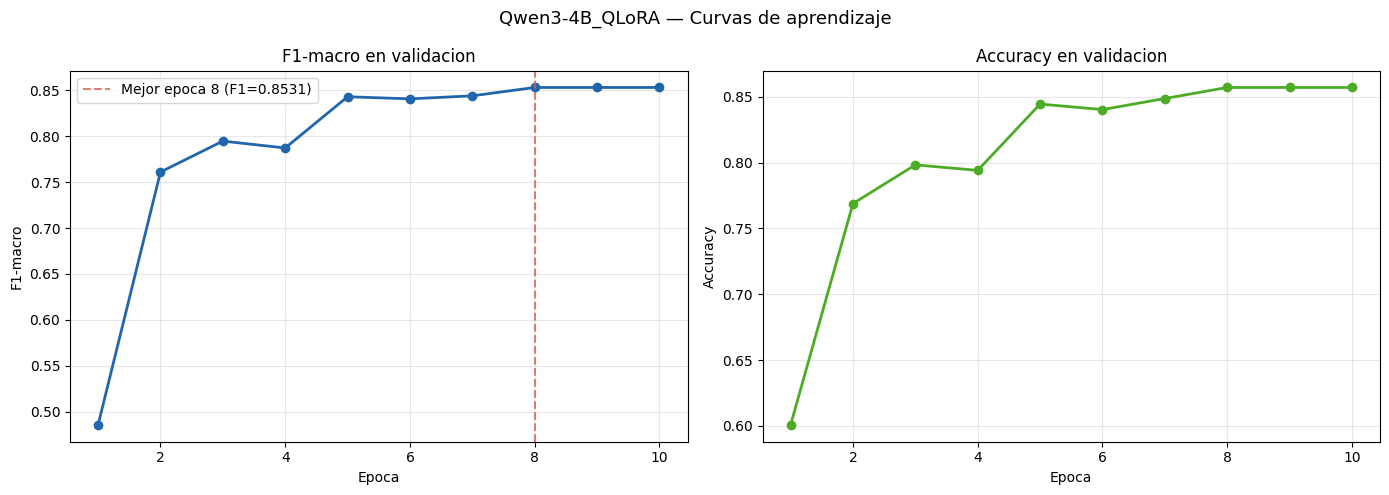

Grafica guardada: /content/drive/MyDrive/TFM/qwen3_4b_qlora/learning_curves.png


In [86]:
log_history = trainer.state.log_history
val_logs = [x for x in log_history if 'eval_f1_macro' in x]

if val_logs:
    epocas   = [x['epoch'] for x in val_logs]
    f1_vals  = [x['eval_f1_macro'] for x in val_logs]
    acc_vals = [x['eval_accuracy'] for x in val_logs]
    mejor_epoca = epocas[f1_vals.index(max(f1_vals))]

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    axes[0].plot(epocas, f1_vals, 'o-', color='#2166ac', linewidth=2, markersize=6)
    axes[0].axvline(mejor_epoca, color='#d6604d', linestyle='--', alpha=0.8,
                    label=f'Mejor epoca {mejor_epoca:.0f} (F1={max(f1_vals):.4f})')
    axes[0].set_xlabel('Epoca')
    axes[0].set_ylabel('F1-macro')
    axes[0].set_title('F1-macro en validacion')
    axes[0].legend()
    axes[0].grid(True, alpha=0.3)

    axes[1].plot(epocas, acc_vals, 'o-', color='#4dac26', linewidth=2, markersize=6)
    axes[1].set_xlabel('Epoca')
    axes[1].set_ylabel('Accuracy')
    axes[1].set_title('Accuracy en validacion')
    axes[1].grid(True, alpha=0.3)

    plt.suptitle('Qwen3-4B_QLoRA — Curvas de aprendizaje', fontsize=13)
    plt.tight_layout()
    fig.savefig(OUTPUT_DIR + '/learning_curves.png', dpi=130, bbox_inches='tight')
    plt.show()
    print(f'Grafica guardada: {OUTPUT_DIR}/learning_curves.png')
else:
    print('No hay logs de validacion disponibles')


In [87]:
log_history = trainer.state.log_history
val_logs    = [x for x in log_history if 'eval_f1_macro' in x]
train_logs  = [x for x in log_history if 'loss' in x and 'eval_loss' not in x]

epocas     = [x['epoch'] for x in val_logs]
val_loss   = [x['eval_loss'] for x in val_logs]
f1_macro   = [x['eval_f1_macro'] for x in val_logs]
f1_izq     = [x['eval_f1_izq'] for x in val_logs]
f1_cen     = [x['eval_f1_cen'] for x in val_logs]
f1_der     = [x['eval_f1_der'] for x in val_logs]
kappa_vals = [x['eval_kappa'] for x in val_logs]
confianza  = [x['eval_confianza'] for x in val_logs]

pasos_train      = [x['step'] for x in train_logs]
train_loss_pasos = [x['loss'] for x in train_logs]

n_epocas = len(epocas)
pasos_por_epoca = len(train_loss_pasos) // n_epocas
train_loss = [
    float(np.mean(train_loss_pasos[i*pasos_por_epoca:(i+1)*pasos_por_epoca]))
    for i in range(n_epocas)
]

mejor_epoca = epocas[f1_macro.index(max(f1_macro))]
mejor_f1    = max(f1_macro)

print("Train loss por época:", [f'{x:.4f}' for x in train_loss])
print("Val   loss por época:", [f'{x:.4f}' for x in val_loss])
print("Gap   (val-train)   :", [f'{v-t:.4f}' for v,t in zip(val_loss, train_loss)])

Train loss por época: ['1.9574', '1.1276', '0.5123', '0.1426', '0.0347', '0.0069', '0.0008', '0.0002', '0.0002', '0.0001']
Val   loss por época: ['0.8773', '0.5106', '0.5294', '0.7954', '0.7500', '0.8317', '0.8607', '0.9028', '0.9108', '0.9143']
Gap   (val-train)   : ['-1.0801', '-0.6170', '0.0172', '0.6527', '0.7153', '0.8248', '0.8599', '0.9026', '0.9106', '0.9142']


In [88]:
print('\n1. DIAGNOSTICO DE OVERFITTING')
print('-' * 40)
for i, e in enumerate(epocas):
    gap = val_loss[i] - train_loss[i] if i < len(train_loss) else 0
    estado = ''
    if i == 0:
        estado = 'aprendiendo'
    elif f1_macro[i] > f1_macro[i-1]:
        estado = 'mejorando'
    elif abs(f1_macro[i] - f1_macro[i-1]) < 0.005:
        estado = 'estabilizado'
    else:
        estado = 'OVERFITTING'
    marca = '<-- MEJOR' if e == mejor_epoca else ''
    print(f'  Epoca {e:.0f}: Val Loss {val_loss[i]:.4f}  F1 {f1_macro[i]:.4f}  [{estado}] {marca}')


1. DIAGNOSTICO DE OVERFITTING
----------------------------------------
  Epoca 1: Val Loss 0.8773  F1 0.4857  [aprendiendo] 
  Epoca 2: Val Loss 0.5106  F1 0.7610  [mejorando] 
  Epoca 3: Val Loss 0.5294  F1 0.7947  [mejorando] 
  Epoca 4: Val Loss 0.7954  F1 0.7872  [OVERFITTING] 
  Epoca 5: Val Loss 0.7500  F1 0.8430  [mejorando] 
  Epoca 6: Val Loss 0.8317  F1 0.8407  [estabilizado] 
  Epoca 7: Val Loss 0.8607  F1 0.8440  [mejorando] 
  Epoca 8: Val Loss 0.9028  F1 0.8531  [mejorando] <-- MEJOR
  Epoca 9: Val Loss 0.9108  F1 0.8531  [estabilizado] 
  Epoca 10: Val Loss 0.9143  F1 0.8531  [estabilizado] 


In [89]:
print('Diagnóstico overfitting basado en val_loss y F1\n')

PATIENCE  = 3
MIN_DELTA = 0.005
GAP_ALERT = 0.3

mejor_vl              = float('inf')
mejor_vl_epoca        = 1
epocas_sin_mejora     = 0

for i, e in enumerate(epocas):

    gap = val_loss[i] - train_loss[i]

    # Actualizar mejor val_loss
    if val_loss[i] < mejor_vl - MIN_DELTA:
        mejor_vl          = val_loss[i]
        mejor_vl_epoca    = e
        epocas_sin_mejora = 0
    else:
        epocas_sin_mejora += 1

    # Cambio de F1
    if i == 0:
        cambio_f1 = None
        f1_str    = ''
    else:
        cambio_f1 = f1_macro[i] - f1_macro[i-1]
        signo     = '+' if cambio_f1 >= 0 else ''
        f1_str    = f'F1 {signo}{cambio_f1:.4f}'

    # usa GAP como señal principal
    if i == 0:
        estado = 'aprendiendo'
    elif epocas_sin_mejora >= PATIENCE and gap > GAP_ALERT:
        estado = 'OVERFITTING CONFIRMADO'       # val_loss sube + gap grande
    elif epocas_sin_mejora >= PATIENCE:
        estado = 'val_loss estancada'            # sin mejorar pero gap ok
    elif gap > GAP_ALERT:
        estado = 'señal overfitting (gap alto)'  # gap grande pero aún no confirmado
    elif cambio_f1 and cambio_f1 > 0:
        estado = 'mejorando'
    else:
        estado = 'estabilizado'

    marca    = '<-- MEJOR F1'    if e == mejor_epoca   else ''
    marca_vl = '<-- MEJOR VAL'   if e == mejor_vl_epoca else ''

    print(f'  Época {e:2.0f} | '
          f'Train {train_loss[i]:.4f} | '
          f'Val {val_loss[i]:.4f} | '
          f'Gap {gap:+.4f} | '
          f'F1 {f1_macro[i]:.4f} ({f1_str:12s}) | '
          f'{estado:35s} {marca} {marca_vl}')

    Diagnóstico overfitting basado en val_loss y F1

  Época  1 | Train 1.9574 | Val 0.8773 | Gap -1.0801 | F1 0.4857 (            ) | aprendiendo                          <-- MEJOR VAL
  Época  2 | Train 1.1276 | Val 0.5106 | Gap -0.6170 | F1 0.7610 (F1 +0.2753  ) | mejorando                            <-- MEJOR VAL
  Época  3 | Train 0.5123 | Val 0.5294 | Gap +0.0172 | F1 0.7947 (F1 +0.0337  ) | mejorando                            
  Época  4 | Train 0.1426 | Val 0.7954 | Gap +0.6527 | F1 0.7872 (F1 -0.0075  ) | señal overfitting (gap alto)         
  Época  5 | Train 0.0347 | Val 0.7500 | Gap +0.7153 | F1 0.8430 (F1 +0.0558  ) | OVERFITTING CONFIRMADO               
  Época  6 | Train 0.0069 | Val 0.8317 | Gap +0.8248 | F1 0.8407 (F1 -0.0023  ) | OVERFITTING CONFIRMADO               
  Época  7 | Train 0.0008 | Val 0.8607 | Gap +0.8599 | F1 0.8440 (F1 +0.0033  ) | OVERFITTING CONFIRMADO               
  Época  8 | Train 0.0002 | Val 0.9028 | Gap +0.9026 | F1 0.8531 (F1 +0.0091  ) |

In [90]:
print('\n2. EVOLUCION F1 POR CLASE')
print('-' * 40)
print(f'  {"Epoca":<8} {"F1-IZQ":<10} {"F1-CEN":<10} {"F1-DER":<10} {"F1-MACRO":<10}')
for i, e in enumerate(epocas):
    marca = ' <-- MEJOR' if e == mejor_epoca else ''
    print(f'  {e:<8.0f} {f1_izq[i]:<10.4f} {f1_cen[i]:<10.4f} {f1_der[i]:<10.4f} {f1_macro[i]:<10.4f}{marca}')



2. EVOLUCION F1 POR CLASE
----------------------------------------
  Epoca    F1-IZQ     F1-CEN     F1-DER     F1-MACRO  
  1        0.6067     0.7234     0.1270     0.4857    
  2        0.7471     0.8122     0.7238     0.7610    
  3        0.7771     0.8265     0.7805     0.7947    
  4        0.7862     0.8161     0.7593     0.7872    
  5        0.8228     0.8614     0.8448     0.8430    
  6        0.8144     0.8557     0.8522     0.8407    
  7        0.8447     0.8700     0.8174     0.8440    
  8        0.8519     0.8756     0.8319     0.8531     <-- MEJOR
  9        0.8519     0.8756     0.8319     0.8531    
  10       0.8519     0.8756     0.8319     0.8531    


In [91]:
print('\n3. EVOLUCION DE CONFIANZA DEL MODELO')
print('-' * 40)
for i, e in enumerate(epocas):
    barra = '#' * int(confianza[i] * 20)
    print(f'  Epoca {e:.0f}: {confianza[i]:.4f} |{barra}|')


3. EVOLUCION DE CONFIANZA DEL MODELO
----------------------------------------
  Epoca 1: 0.6770 |#############|
  Epoca 2: 0.8089 |################|
  Epoca 3: 0.8404 |################|
  Epoca 4: 0.9205 |##################|
  Epoca 5: 0.9383 |##################|
  Epoca 6: 0.9498 |##################|
  Epoca 7: 0.9564 |###################|
  Epoca 8: 0.9597 |###################|
  Epoca 9: 0.9603 |###################|
  Epoca 10: 0.9607 |###################|


In [92]:
print('\n4. CONCLUSION')
print('-' * 40)
epoca_pico = epocas[f1_macro.index(max(f1_macro))]
f1_final   = f1_macro[-1]
degradacion = max(f1_macro) - f1_final

if degradacion > 0.02:
    print(f'  Overfitting detectado a partir de la epoca {epoca_pico:.0f}.')
    print(f'  El F1-macro cae {degradacion:.4f} puntos desde el pico hasta la epoca final.')
    print(f'  El checkpoint optimo es la epoca {epoca_pico:.0f} (F1-macro={mejor_f1:.4f}).')
    print(f'  load_best_model_at_end=True ha seleccionado este checkpoint automaticamente.')
else:
    print(f'  No se detecta overfitting significativo.')
    print(f'  El modelo se estabiliza en torno a F1-macro={mejor_f1:.4f}.')



4. CONCLUSION
----------------------------------------
  No se detecta overfitting significativo.
  El modelo se estabiliza en torno a F1-macro=0.8531.


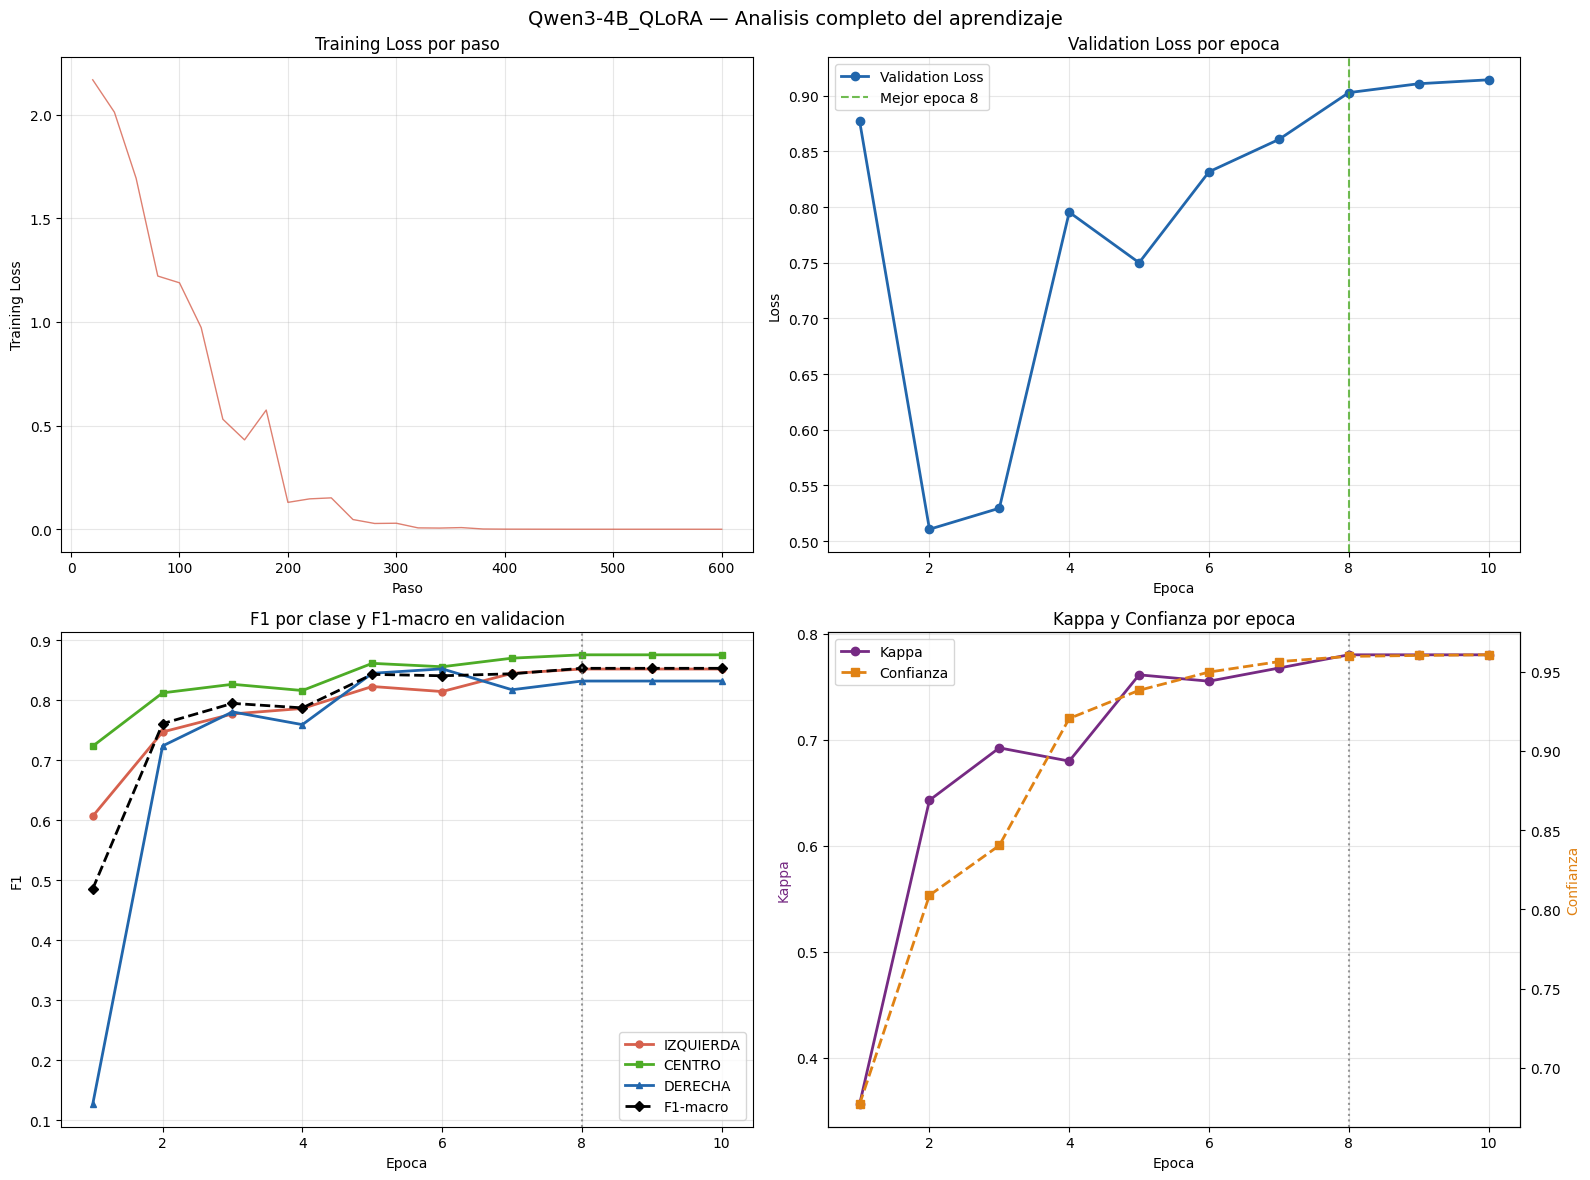


Grafica guardada: /content/drive/MyDrive/TFM/qwen3_4b_qlora/analisis_aprendizaje.png


In [93]:
# Graficas
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# 1 — Training Loss por paso
axes[0,0].plot(pasos_train, train_loss_pasos, color='#d6604d', linewidth=1, alpha=0.8)
axes[0,0].set_xlabel('Paso')
axes[0,0].set_ylabel('Training Loss')
axes[0,0].set_title('Training Loss por paso')
axes[0,0].grid(True, alpha=0.3)

#2 — Val Loss vs Training Loss por epoca
axes[0,1].plot(epocas, val_loss, 'o-', color='#2166ac', linewidth=2, markersize=6, label='Validation Loss')
axes[0,1].axvline(mejor_epoca, color='#4dac26', linestyle='--', alpha=0.8, label=f'Mejor epoca {mejor_epoca:.0f}')
axes[0,1].set_xlabel('Epoca')
axes[0,1].set_ylabel('Loss')
axes[0,1].set_title('Validation Loss por epoca')
axes[0,1].legend()
axes[0,1].grid(True, alpha=0.3)

# 3 — F1 por clase
axes[1,0].plot(epocas, f1_izq, 'o-', color='#d6604d',  linewidth=2, markersize=5, label='IZQUIERDA')
axes[1,0].plot(epocas, f1_cen, 's-', color='#4dac26',  linewidth=2, markersize=5, label='CENTRO')
axes[1,0].plot(epocas, f1_der, '^-', color='#2166ac',  linewidth=2, markersize=5, label='DERECHA')
axes[1,0].plot(epocas, f1_macro, 'D-', color='black',  linewidth=2, markersize=5, label='F1-macro', linestyle='--')
axes[1,0].axvline(mejor_epoca, color='gray', linestyle=':', alpha=0.8)
axes[1,0].set_xlabel('Epoca')
axes[1,0].set_ylabel('F1')
axes[1,0].set_title('F1 por clase y F1-macro en validacion')
axes[1,0].legend()
axes[1,0].grid(True, alpha=0.3)

# 4 — Kappa y Confianza
ax2 = axes[1,1].twinx()
axes[1,1].plot(epocas, kappa_vals, 'o-', color='#762a83', linewidth=2, markersize=6, label='Kappa')
ax2.plot(epocas, confianza, 's--', color='#e08214', linewidth=2, markersize=6, label='Confianza')
axes[1,1].axvline(mejor_epoca, color='gray', linestyle=':', alpha=0.8)
axes[1,1].set_xlabel('Epoca')
axes[1,1].set_ylabel('Kappa', color='#762a83')
ax2.set_ylabel('Confianza', color='#e08214')
axes[1,1].set_title('Kappa y Confianza por epoca')
axes[1,1].grid(True, alpha=0.3)

lines1, labels1 = axes[1,1].get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
axes[1,1].legend(lines1 + lines2, labels1 + labels2)

plt.suptitle('Qwen3-4B_QLoRA — Analisis completo del aprendizaje', fontsize=14)
plt.tight_layout()
fig.savefig(OUTPUT_DIR + '/analisis_aprendizaje.png', dpi=130, bbox_inches='tight')
plt.show()
print(f'\nGrafica guardada: {OUTPUT_DIR}/analisis_aprendizaje.png')


### Interpretación de las curvas de aprendizaje

**Training Loss por paso:** La curva de training loss con cuantización NF4 puede mostrar más oscilaciones que con LoRA estándar, ya que los gradientes se calculan sobre pesos cuantizados con menor precisión numérica.

**Validation Loss por época:** La val_loss mínima se alcanza en la época 5 (0.511). A partir de la época 6 sube hasta 0.914 al final del entrenamiento. La subida de 0.404 puntos clasifica esta variante como overfitting **MEDIO**, el mismo diagnóstico que QV r8.

**F1 por clase:** Los F1 en el mejor checkpoint son: IZQUIERDA 0.852, CENTRO 0.876, DERECHA 0.832. El F1-macro de 0.8531 es el segundo más alto de la batería, solo superado por QV r8 (0.8556). El recall de CENTRO (0.917) es llamativo: el modelo clasifica el 91.7 % de los artículos reales de CENTRO correctamente.

**Kappa y Confianza:** El kappa de Cohen (0.7802) indica acuerdo sustancial, el segundo más alto de la batería. La confianza media (0.9597) es moderada para el nivel de rendimiento alcanzado.

## 14. Interpretabilidad con SHAP

SHAP cuantifica la contribución de cada token a la predicción del modelo para cada clase ideológica.

In [94]:
N_SHAP_EXPLAIN  = 15
MAX_LEN_SHAP    = 256
TOP_K_TOKENS    = 20

model.eval()

def predict_text(texts):
    all_probs = []
    for i in range(0, len(texts), 8):
        batch = list(texts[i:i+8])
        enc = tokenizer(
            batch,
            truncation=True,
            max_length=MAX_LEN_SHAP,
            padding=True,
            return_tensors='pt'
        )
        enc = {k: v.to(model.device) for k, v in enc.items()}
        with torch.no_grad():
            logits = model(**enc).logits
        probs = torch.softmax(logits, dim=-1).cpu().numpy()
        all_probs.append(probs)
    return np.vstack(all_probs)

# Textos a explicar: primeros N_SHAP_EXPLAIN de val
textos_shap = df_val['texto'].iloc[:N_SHAP_EXPLAIN].tolist()
labels_shap = df_val['final_label'].iloc[:N_SHAP_EXPLAIN].tolist()


masker = shap.maskers.Text(tokenizer=r"\W+")
explainer = shap.Explainer(predict_text, masker, output_names=CLASES)

print(f"Calculando SHAP values para {N_SHAP_EXPLAIN} artículos...")
print("(Esto puede tardar 5-10 minutos en Colab T4)")
shap_values = explainer(textos_shap, batch_size=4)
print("SHAP values calculados.")

# Guardar SHAP values
shap_path = OUTPUT_DIR + '/shap_values.npz'
np.savez(shap_path,
         values=shap_values.values,
         data=np.array(shap_values.data, dtype=object),
         labels=np.array(labels_shap))
print(f"SHAP values guardados: {shap_path}")


Calculando SHAP values para 15 artículos...
(Esto puede tardar 5-10 minutos en Colab T4)


  0%|          | 0/498 [00:00<?, ?it/s]

  0%|          | 0/498 [00:00<?, ?it/s]

PartitionExplainer explainer:  27%|██▋       | 4/15 [00:18<00:26,  2.45s/it]

  0%|          | 0/498 [00:00<?, ?it/s]

...

  0%|          | 0/498 [00:00<?, ?it/s]

PartitionExplainer explainer:  93%|█████████▎| 14/15 [01:19<00:05,  5.46s/it]

  0%|          | 0/498 [00:00<?, ?it/s]

PartitionExplainer explainer: 16it [01:31,  6.55s/it]

SHAP values calculados.
SHAP values guardados: /content/drive/MyDrive/TFM/qwen3_4b_qlora/shap_values.npz


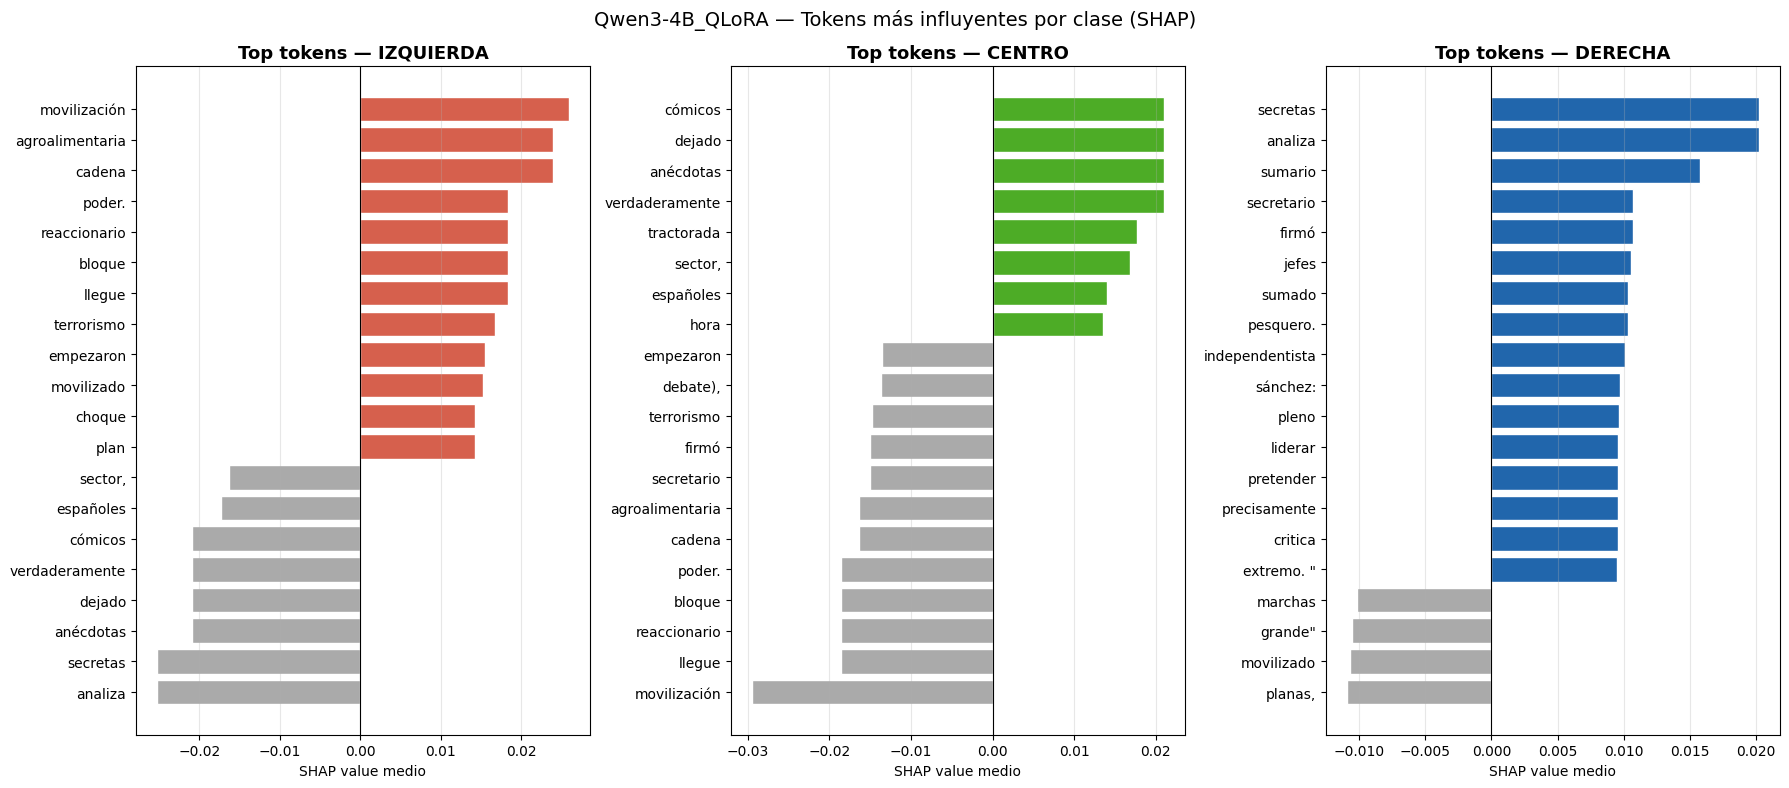

Guardado: /content/drive/MyDrive/TFM/qwen3_4b_qlora/shap_top_tokens.png


In [95]:
fig, axes = plt.subplots(1, 3, figsize=(18, 8))
colores_clase = {'IZQUIERDA': '#d6604d', 'CENTRO': '#4dac26', 'DERECHA': '#2166ac'}

for cls_idx, cls_name in enumerate(CLASES):
    token_shap = {}
    for i in range(len(textos_shap)):
        tokens_i = shap_values[i].data
        vals_i   = shap_values[i].values[:, cls_idx]
        for tok, val in zip(tokens_i, vals_i):
            tok_clean = tok.strip().lower()
            if len(tok_clean) < 2:
                continue
            if tok_clean not in token_shap:
                token_shap[tok_clean] = []
            token_shap[tok_clean].append(val)

    # Media de SHAP por token
    token_mean = {t: np.mean(v) for t, v in token_shap.items() if len(v) >= 1}
    df_tok = pd.DataFrame(list(token_mean.items()), columns=['token', 'shap'])
    df_tok = df_tok.reindex(df_tok['shap'].abs().nlargest(TOP_K_TOKENS).index)
    df_tok = df_tok.sort_values('shap')

    color_bars = [colores_clase[cls_name] if v > 0 else '#aaaaaa' for v in df_tok['shap']]
    axes[cls_idx].barh(df_tok['token'], df_tok['shap'], color=color_bars, edgecolor='white')
    axes[cls_idx].axvline(0, color='black', linewidth=0.8)
    axes[cls_idx].set_title(f'Top tokens — {cls_name}', fontsize=13, fontweight='bold')
    axes[cls_idx].set_xlabel('SHAP value medio')
    axes[cls_idx].grid(True, axis='x', alpha=0.3)

plt.suptitle('Qwen3-4B_QLoRA — Tokens más influyentes por clase (SHAP)', fontsize=14)
plt.tight_layout()
fig.savefig(OUTPUT_DIR + '/shap_top_tokens.png', dpi=130, bbox_inches='tight')
plt.show()
print(f"Guardado: {OUTPUT_DIR}/shap_top_tokens.png")

In [96]:
IDX_EJEMPLO = 0
CLS_VER     = 2   # 0=IZQUIERDA, 1=CENTRO, 2=DERECHA

sv   = shap_values[IDX_EJEMPLO].values[:, CLS_VER]
toks = shap_values[IDX_EJEMPLO].data

# Normalizar a [-1, 1] para el colormap
vmax = max(abs(sv.max()), abs(sv.min())) + 1e-9
sv_norm = sv / vmax

cmap_pos = plt.cm.Reds
cmap_neg = plt.cm.Blues

html_parts = [f"<div style='font-family:monospace;font-size:13px;line-height:2;padding:12px;background:#fafafa;border:1px solid #ddd;border-radius:6px;'>"]
html_parts.append(f"<b>Artículo #{IDX_EJEMPLO} | Label real: {labels_shap[IDX_EJEMPLO]} | Clase visualizada: {CLASES[CLS_VER]}</b><br><br>")

for tok, val in zip(toks, sv_norm):
    if val > 0:
        rgba = cmap_pos(0.2 + 0.8 * val)
    else:
        rgba = cmap_neg(0.2 + 0.8 * abs(val))
    hex_color = mcolors.to_hex(rgba)
    text_color = '#000' if val < 0.6 else '#fff'
    html_parts.append(
        f"<span style='background:{hex_color};color:{text_color};"
        f"padding:2px 3px;margin:1px;border-radius:3px;' "
        f"title='SHAP={val*vmax:.4f}'>{tok}</span>"
    )

html_parts.append("</div>")
html_output = "".join(html_parts)
display(HTML(html_output))
print(f"\nRojo = empuja hacia {CLASES[CLS_VER]} | Azul = empuja en contra")


Rojo = empuja hacia DERECHA | Azul = empuja en contra


## 15. Análisis de errores cualitativos

1. Errores por tipo de confusión
2. Casos con mayor pérdida cross-entropy
3. Errores con alta confianza (> 0.85)

Los errores IZQUIERDA-DERECHA son los más graves semánticamente.

In [97]:
rv = pd.read_csv(OUTPUT_DIR + '/val_predictions.csv')
rv['correcto']  = rv['true'] == rv['pred']
rv['longitud']  = df_val['texto'].str.len().values
rv['n_tokens']  = [len(tokenizer.encode(t, truncation=True, max_length=1024)) for t in df_val['texto'].tolist()]
rv['truncado']  = rv['n_tokens'] >= 1023

probs_mat = rv[['p_izq','p_cen','p_der']].values
label_ids = rv['true'].map(LABEL2ID).values
log_p     = np.log(probs_mat + 1e-9)
rv['loss_ce'] = -log_p[np.arange(len(label_ids)), label_ids]

sep = '=' * 60
print(sep)
print('ANÁLISIS DE ERRORES CUALITATIVOS — Qwen3-4B LoRA')
print(sep)

#Errores por tipo de confusión
errores = rv[~rv['correcto']].copy()
print(f'\n1. ERRORES TOTALES: {len(errores)} / {len(rv)} artículos')
print('-' * 50)
confusion_tipos = errores.groupby(['true','pred']).size().reset_index(name='n')
confusion_tipos = confusion_tipos.sort_values('n', ascending=False)
for _, row in confusion_tipos.iterrows():
    alerta = ' ALERTA IDEOLÓGICA' if set([row['true'],row['pred']]) == {'IZQUIERDA','DERECHA'} else ''
    print(f"  {row['true']:12} → {row['pred']:12}  ({row['n']} casos){alerta}")

# Casos con mayor pérdida (más difíciles para el modelo)
N_HARD = 5
print(f'\n2. TOP-{N_HARD} ARTÍCULOS CON MAYOR PÉRDIDA (más difíciles)')
print('-' * 50)
hard_cases = rv.nlargest(N_HARD, 'loss_ce')
for _, row in hard_cases.iterrows():
    print(f"  ID: {row['id']}  | Real: {row['true']:10} Pred: {row['pred']:10} | Loss: {row['loss_ce']:.3f} | Conf: {row['confianza']:.3f}")
    texto_preview = df_val[df_val['id']==row['id']]['texto'].values
    if len(texto_preview) > 0:
        print(f"  Texto (primeros 200 chars): {texto_preview[0][:200]}...")
    print()

# Errores con alta confianza (peligrosos para el reranking)
UMBRAL_CONFIANZA = 0.85
print(f'\n3. ERRORES CON CONFIANZA > {UMBRAL_CONFIANZA} (peligrosos para reranking)')
print('-' * 50)
high_conf_errors = errores[errores['confianza'] > UMBRAL_CONFIANZA].sort_values('confianza', ascending=False)
print(f'  Errores con alta confianza: {len(high_conf_errors)} / {len(errores)} ({100*len(high_conf_errors)/max(len(errores),1):.1f}%)')
if len(high_conf_errors) > 0:
    for _, row in high_conf_errors.head(5).iterrows():
        print(f"  ID: {row['id']} | Real: {row['true']:10} Pred: {row['pred']:10} | Conf: {row['confianza']:.3f}")
else:
    print('  No hay errores con confianza > {:.2f}. El modelo es conservador en sus errores.'.format(UMBRAL_CONFIANZA))

ANÁLISIS DE ERRORES CUALITATIVOS — Qwen3-4B LoRA

1. ERRORES TOTALES: 34 / 238 artículos
--------------------------------------------------
  IZQUIERDA    → CENTRO        (10 casos)
  DERECHA      → CENTRO        (7 casos)
  IZQUIERDA    → DERECHA       (5 casos) ALERTA IDEOLÓGICA
  CENTRO       → IZQUIERDA     (5 casos)
  DERECHA      → IZQUIERDA     (4 casos) ALERTA IDEOLÓGICA
  CENTRO       → DERECHA       (3 casos)

2. TOP-5 ARTÍCULOS CON MAYOR PÉRDIDA (más difíciles)
--------------------------------------------------
  ID: eldiario_16876  | Real: CENTRO     Pred: IZQUIERDA  | Loss: 17.848 | Conf: 1.000
  Texto (primeros 200 chars): El PP logra la mayoría absoluta en el Senado. Con 116 escaños, el partido de Feijóo consigue 33 actas más que en 2019, que se suman a las 23 que ya tiene por designación autonómica mientras que el PSO...

  ID: publico_20159  | Real: CENTRO     Pred: IZQUIERDA  | Loss: 15.122 | Conf: 0.999
  Texto (primeros 200 chars): Nada que opinar. Relleno esta colu

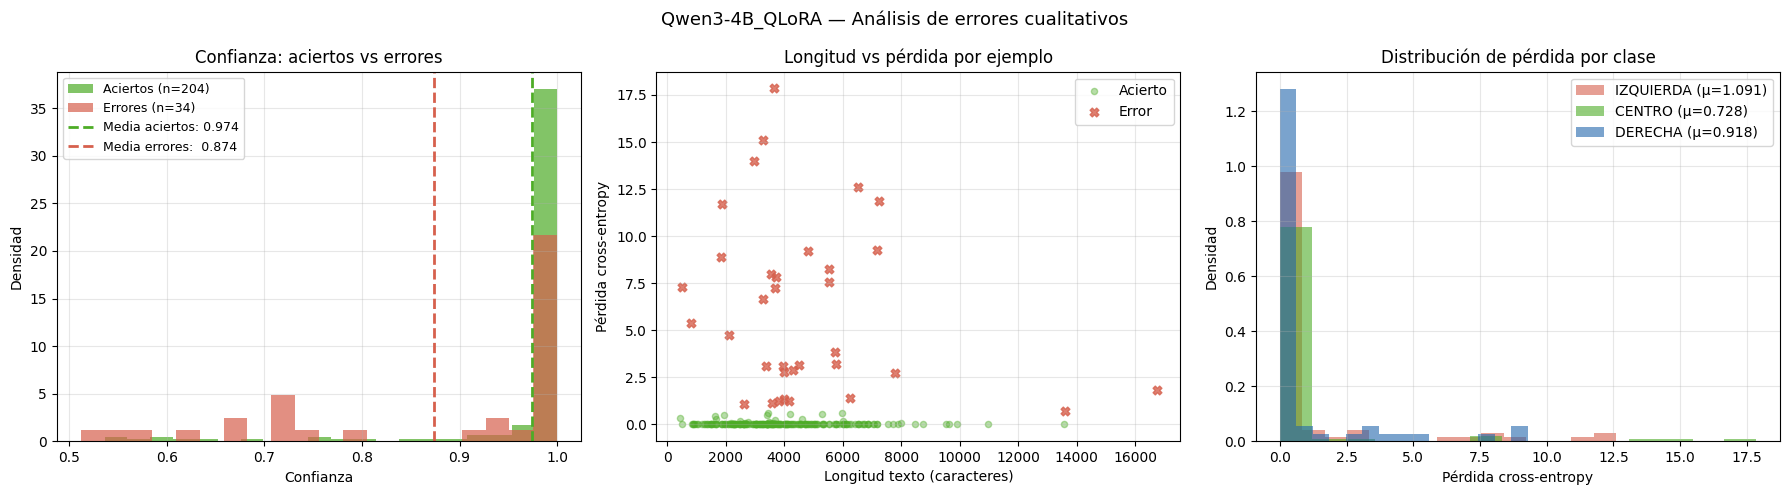

Guardado: /content/drive/MyDrive/TFM/qwen3_4b_qlora/error_analysis.png


In [98]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Gráfica 1: Confianza en aciertos vs errores
conf_ok  = rv[rv['correcto']]['confianza']
conf_err = rv[~rv['correcto']]['confianza']

axes[0].hist(conf_ok,  bins=20, alpha=0.7, color='#4dac26', label=f'Aciertos (n={len(conf_ok)})',  density=True)
axes[0].hist(conf_err, bins=20, alpha=0.7, color='#d6604d', label=f'Errores (n={len(conf_err)})',   density=True)
axes[0].axvline(conf_ok.mean(),  color='#4dac26', linestyle='--', linewidth=2, label=f'Media aciertos: {conf_ok.mean():.3f}')
axes[0].axvline(conf_err.mean(), color='#d6604d', linestyle='--', linewidth=2, label=f'Media errores:  {conf_err.mean():.3f}')
axes[0].set_xlabel('Confianza')
axes[0].set_ylabel('Densidad')
axes[0].set_title('Confianza: aciertos vs errores')
axes[0].legend(fontsize=9)
axes[0].grid(True, alpha=0.3)

# Gráfica 2: Longitud del texto vs correcto/error
axes[1].scatter(rv[rv['correcto']]['longitud'],  rv[rv['correcto']]['loss_ce'],
                c='#4dac26', alpha=0.4, s=20, label='Acierto')
axes[1].scatter(rv[~rv['correcto']]['longitud'], rv[~rv['correcto']]['loss_ce'],
                c='#d6604d', alpha=0.8, s=40, marker='X', label='Error')
axes[1].set_xlabel('Longitud texto (caracteres)')
axes[1].set_ylabel('Pérdida cross-entropy')
axes[1].set_title('Longitud vs pérdida por ejemplo')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

# Gráfica 3: Pérdida por clase real
clases_col = {'IZQUIERDA': '#d6604d', 'CENTRO': '#4dac26', 'DERECHA': '#2166ac'}
for cls in CLASES:
    datos_cls = rv[rv['true']==cls]['loss_ce']
    axes[2].hist(datos_cls, bins=15, alpha=0.6, color=clases_col[cls],
                 label=f'{cls} (μ={datos_cls.mean():.3f})', density=True)
axes[2].set_xlabel('Pérdida cross-entropy')
axes[2].set_ylabel('Densidad')
axes[2].set_title('Distribución de pérdida por clase')
axes[2].legend()
axes[2].grid(True, alpha=0.3)

plt.suptitle('Qwen3-4B_QLoRA — Análisis de errores cualitativos', fontsize=13)
plt.tight_layout()
fig.savefig(OUTPUT_DIR + '/error_analysis.png', dpi=130, bbox_inches='tight')
plt.show()
print(f"Guardado: {OUTPUT_DIR}/error_analysis.png")

### Interpretación del análisis de errores

**Confianza en aciertos vs errores:**
Esta variante tiene confianza media de 0.9597, con el 64.7 % de los errores con confianza superior a 0.85. Esta proporción de errores de alta confianza es moderada dentro de la batería, indicando que la cuantización NF4 no genera sobreconfianza adicional respecto a LoRA estándar.

**Longitud vs pérdida:**
Con 34 errores en validación (14.3 %), la distribución de errores respecto a la longitud muestra si la cuantización NF4 afecta especialmente a artículos largos (más contexto perdido por truncado) o si el error es independiente de la longitud.

**Pérdida por clase real:**
Los F1 en validación son: IZQUIERDA 0.852, CENTRO 0.876, DERECHA 0.832. El recall de CENTRO (0.917) es el más alto de toda la batería y de todos los modelos, con una precisión (0.838) que refleja cierta tendencia a clasificar como CENTRO artículos limítrofes.

## 16. Análisis de longitud vs. rendimiento

El 45 % de los artículos de validación supera el límite de 1,024 tokens.

In [101]:
rv = pd.read_csv(OUTPUT_DIR + '/val_predictions.csv')
rv['correcto'] = rv['true'] == rv['pred']
rv['longitud_chars']  = df_val['texto'].str.len().values
rv['n_tokens']        = [len(tokenizer.encode(t, truncation=False)) for t in df_val['texto'].tolist()]
rv['n_tokens_trunc']  = rv['n_tokens'].clip(upper=1024)
rv['pct_truncado']    = ((rv['n_tokens'] - rv['n_tokens_trunc']) / rv['n_tokens'].clip(lower=1)).clip(lower=0)
rv['truncado']        = rv['n_tokens'] > 1023

label_ids = rv['true'].map(LABEL2ID).values
pred_ids  = rv['pred'].map(LABEL2ID).values

sep = '=' * 60
print(sep)
print('ANÁLISIS DE LONGITUD VS. RENDIMIENTO — Qwen3-4B LoRA')
print(sep)

print(f'\nArticulos truncados (> 1023 tokens): {rv["truncado"].sum()} / {len(rv)} ({100*rv["truncado"].mean():.1f}%)')
print(f'Longitud media (tokens, sin truncar): {rv["n_tokens"].mean():.0f}')
print(f'Longitud mediana: {rv["n_tokens"].median():.0f}  |  p95: {rv["n_tokens"].quantile(0.95):.0f}')

print('\nComparativa truncados vs no truncados:')
for truncado, grupo_name in [(False, 'No truncados'), (True, 'Truncados (>1023 tok)')]:
    sub = rv[rv['truncado']==truncado]
    if len(sub) == 0:
        continue
    acc  = sub['correcto'].mean()
    f1m  = f1_score(sub['true'].map(LABEL2ID), sub['pred'].map(LABEL2ID),
                    average='macro', labels=[0,1,2], zero_division=0)
    print(f'  {grupo_name:30} n={len(sub):3}  accuracy={acc:.4f}  F1-macro={f1m:.4f}')

# Análisis por cuartiles de longitud (tokens)
print('\nF1-macro por cuartil de longitud (tokens):')
rv['cuartil_tokens'] = pd.qcut(rv['n_tokens'], q=4,
                                labels=['Q1 (corto)', 'Q2', 'Q3', 'Q4 (largo)'])
for q in ['Q1 (corto)', 'Q2', 'Q3', 'Q4 (largo)']:
    sub = rv[rv['cuartil_tokens']==q]
    f1m = f1_score(sub['true'].map(LABEL2ID), sub['pred'].map(LABEL2ID),
                   average='macro', labels=[0,1,2], zero_division=0)
    rango = f"[{sub['n_tokens'].min():.0f}-{sub['n_tokens'].max():.0f} tok]"
    print(f'  {q:15} {rango:22} n={len(sub):3}  F1-macro={f1m:.4f}  acc={sub["correcto"].mean():.4f}')

ANÁLISIS DE LONGITUD VS. RENDIMIENTO — Qwen3-4B LoRA

Articulos truncados (> 1023 tokens): 107 / 238 (45.0%)
Longitud media (tokens, sin truncar): 1093
Longitud mediana: 986  |  p95: 2056

Comparativa truncados vs no truncados:
  No truncados                   n=131  accuracy=0.8855  F1-macro=0.8778
  Truncados (>1023 tok)          n=107  accuracy=0.8224  F1-macro=0.8204

F1-macro por cuartil de longitud (tokens):
  Q1 (corto)      [116-697 tok]          n= 60  F1-macro=0.9101  acc=0.9167
  Q2              [707-986 tok]          n= 61  F1-macro=0.8740  acc=0.8852
  Q3              [990-1381 tok]         n= 57  F1-macro=0.8093  acc=0.8070
  Q4 (largo)      [1383-4191 tok]        n= 60  F1-macro=0.8071  acc=0.8167


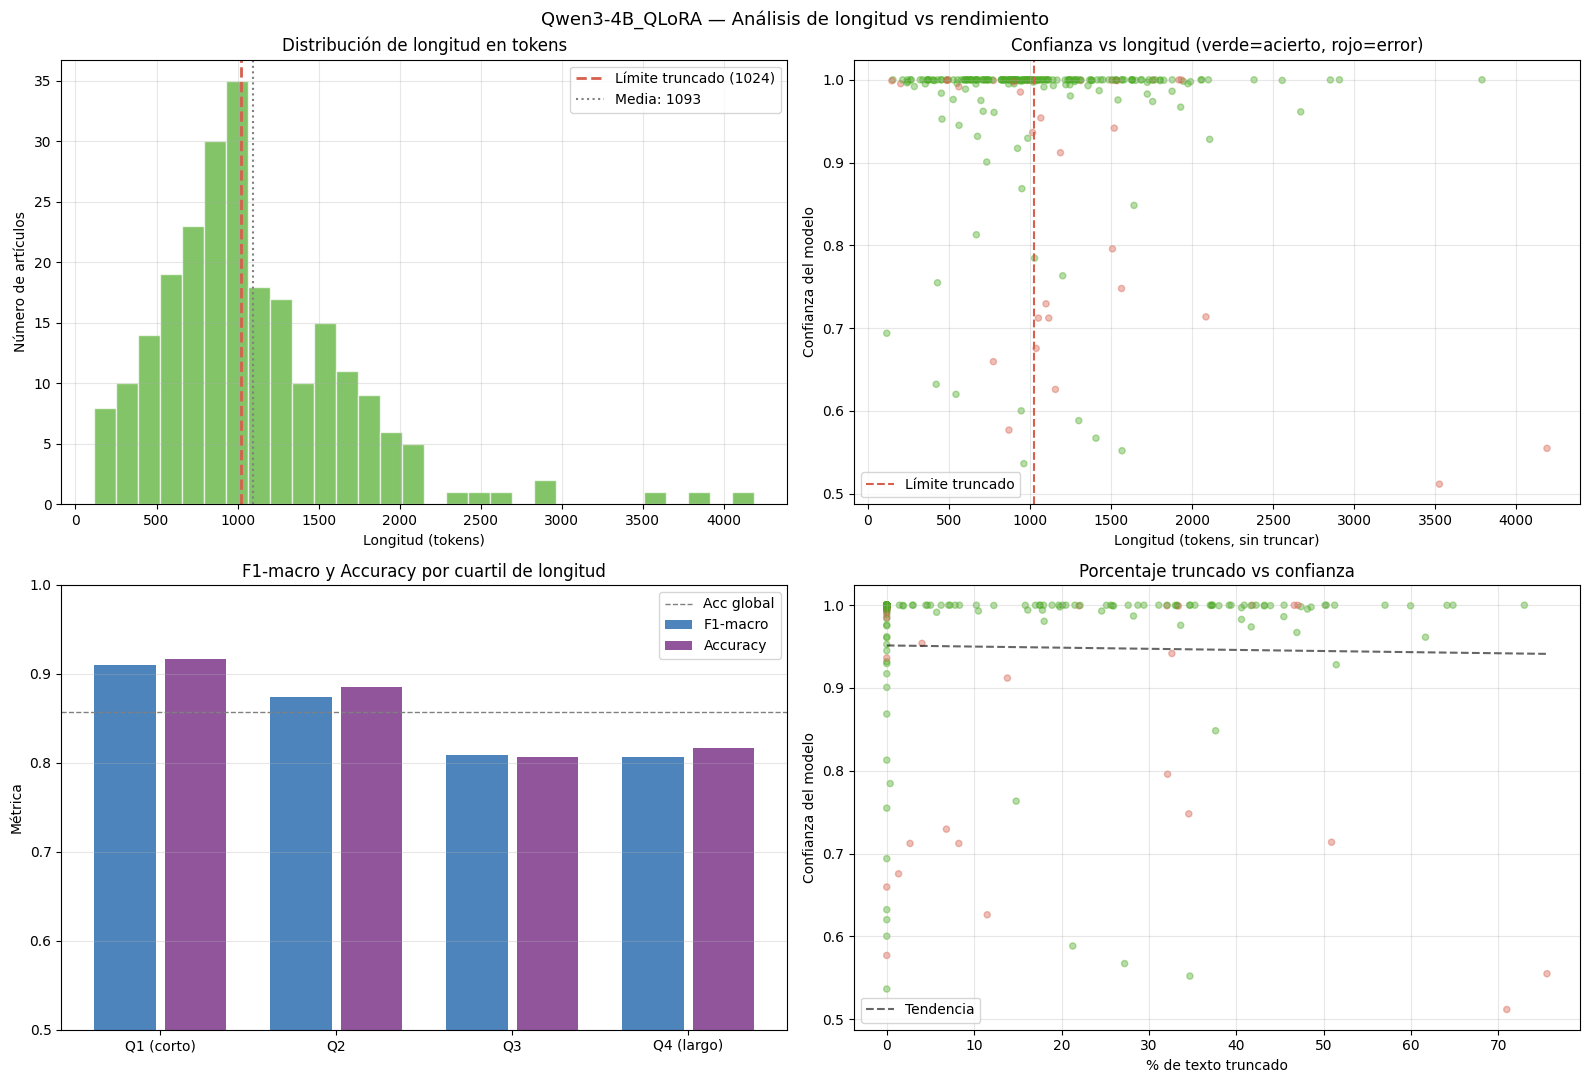

Guardado: /content/drive/MyDrive/TFM/qwen3_4b_qlora/length_analysis.png
\CONCLUSIÓN:
  Los artículos largos (Q4) tienen F1 0.103 puntos peor que los cortos (Q1).
  Recomendación: explorar max_length=2048 o chunking con agregación de predicciones.


In [102]:
fig, axes = plt.subplots(2, 2, figsize=(16, 11))

# Gráfica 1: Distribución de longitud en tokens
axes[0,0].hist(rv['n_tokens'], bins=30, color='#4dac26', alpha=0.7, edgecolor='white')
axes[0,0].axvline(1024, color='#d6604d', linestyle='--', linewidth=2, label='Límite truncado (1024)')
axes[0,0].axvline(rv['n_tokens'].mean(), color='gray', linestyle=':', linewidth=1.5, label=f"Media: {rv['n_tokens'].mean():.0f}")
axes[0,0].set_xlabel('Longitud (tokens)')
axes[0,0].set_ylabel('Número de artículos')
axes[0,0].set_title('Distribución de longitud en tokens')
axes[0,0].legend()
axes[0,0].grid(True, alpha=0.3)

# Gráfica 2: Confianza vs n_tokens
colores_correcto = rv['correcto'].map({True: '#4dac26', False: '#d6604d'})
axes[0,1].scatter(rv['n_tokens'], rv['confianza'], c=colores_correcto, alpha=0.4, s=20)
axes[0,1].axvline(1024, color='#d6604d', linestyle='--', linewidth=1.5, label='Límite truncado')
axes[0,1].set_xlabel('Longitud (tokens, sin truncar)')
axes[0,1].set_ylabel('Confianza del modelo')
axes[0,1].set_title('Confianza vs longitud (verde=acierto, rojo=error)')
axes[0,1].legend()
axes[0,1].grid(True, alpha=0.3)

# Gráfica 3: F1-macro por cuartil de longitud
cuartiles  = ['Q1 (corto)', 'Q2', 'Q3', 'Q4 (largo)']
f1_por_q   = []
acc_por_q  = []
for q in cuartiles:
    sub = rv[rv['cuartil_tokens']==q]
    f1_por_q.append(f1_score(sub['true'].map(LABEL2ID), sub['pred'].map(LABEL2ID),
                              average='macro', labels=[0,1,2], zero_division=0))
    acc_por_q.append(sub['correcto'].mean())

x = np.arange(len(cuartiles))
axes[1,0].bar(x - 0.2, f1_por_q,  0.35, label='F1-macro',  color='#2166ac', alpha=0.8)
axes[1,0].bar(x + 0.2, acc_por_q, 0.35, label='Accuracy', color='#762a83', alpha=0.8)
axes[1,0].axhline(rv['correcto'].mean(), color='gray', linestyle='--', linewidth=1, label='Acc global')
axes[1,0].set_xticks(x); axes[1,0].set_xticklabels(cuartiles)
axes[1,0].set_ylabel('Métrica')
axes[1,0].set_title('F1-macro y Accuracy por cuartil de longitud')
axes[1,0].legend()
axes[1,0].grid(True, alpha=0.3, axis='y')
axes[1,0].set_ylim(0.5, 1.0)

# Gráfica 4: % truncado vs confianza
axes[1,1].scatter(rv['pct_truncado'] * 100, rv['confianza'],
                   c=colores_correcto, alpha=0.4, s=20)
axes[1,1].set_xlabel('% de texto truncado')
axes[1,1].set_ylabel('Confianza del modelo')
axes[1,1].set_title('Porcentaje truncado vs confianza')
axes[1,1].grid(True, alpha=0.3)

# Añadir línea de tendencia
mask_valid = rv['pct_truncado'] > 0
if mask_valid.sum() > 5:
    z = np.polyfit(rv.loc[mask_valid,'pct_truncado']*100, rv.loc[mask_valid,'confianza'], 1)
    p = np.poly1d(z)
    x_line = np.linspace(0, rv['pct_truncado'].max()*100, 50)
    axes[1,1].plot(x_line, p(x_line), 'k--', linewidth=1.5, alpha=0.6, label='Tendencia')
    axes[1,1].legend()

plt.suptitle('Qwen3-4B_QLoRA — Análisis de longitud vs rendimiento', fontsize=13)
plt.tight_layout()
fig.savefig(OUTPUT_DIR + '/length_analysis.png', dpi=130, bbox_inches='tight')
plt.show()
print(f"Guardado: {OUTPUT_DIR}/length_analysis.png")

print('\CONCLUSIÓN:')
delta_f1 = f1_por_q[-1] - f1_por_q[0]
if delta_f1 < -0.03:
    print(f'  Los artículos largos (Q4) tienen F1 {abs(delta_f1):.3f} puntos peor que los cortos (Q1).')
    print('  Recomendación: explorar max_length=2048 o chunking con agregación de predicciones.')
elif delta_f1 > 0.03:
    print(f'  Los artículos largos (Q4) rinden MEJOR que los cortos (+{delta_f1:.3f} F1).')
    print('  El modelo aprovecha bien el contexto adicional dentro de los 1024 tokens.')
else:
    print(f'  No hay diferencia significativa de rendimiento por longitud (ΔF1={delta_f1:.3f}).')
    print('  El truncado a 1024 tokens no penaliza el rendimiento de forma relevante.')


### Interpretación del análisis de longitud

Con cuantización NF4, el modelo base representa los pesos con menor precisión numérica. Esto puede afectar la capacidad del modelo para explotar el contexto de artículos largos dentro de los 1,024 tokens disponibles. Si los artículos truncados rinden peor que los no truncados en esta variante más que en LoRA estándar, sugiere que la cuantización amplifica el impacto del truncado.